# Making a KernelAbstractions.jl kernel faster

We pick up the Mandelbrot kernel from the
[KA tutorial](https://github.com/cwittens/A_KernelAbstractions_Tutorial) and make it faster,
one change at a time. Every step is benchmarked against the previous one, and every
step is checked against a reference result.

The setup is the one from lab 2 of MIT's 6.S894
([accelerated-computing.academy](https://accelerated-computing.academy/fall24/)):
an 8192 × 8192 image of a tiny window (width 10⁻⁴) in the "Seahorse Valley" of the
Mandelbrot set, with at most 2000 iterations per pixel. So the numbers here can be
compared directly with the CUDA versions from that course.

1. Types: Float32 instead of Float64, and when Float32 is not good enough.
2. The speed limit: how fast could we possibly be, if we only had to move the data?
3. Launch configuration: a static workgroup size.
4. Arithmetic: real numbers instead of `Complex`, and `muladd`.
5. Control flow: a branchless inner loop that only checks for escape every K steps.
6. Divergence: how much time do lanes spend waiting, and can we group pixels better?
7. Memory: write fewer bytes, and see why it barely matters here.

## Setup

In [1]:
using KernelAbstractions
using CUDA
using Adapt: adapt
using BenchmarkTools, Printf
using Plots

backend = CUDABackend()
# backend = ROCBackend()      # AMD
# backend = MetalBackend()    # Apple
# backend = CPU()             # no GPU needed

CUDABackend(false, false)

Which GPU are we running on?

In [2]:
println(CUDA.name(CUDA.device()))

NVIDIA L40S


A small benchmark helper. Kernel launches are asynchronous, so we synchronize
inside the timed region. The first call compiles and is not timed. `@belapsed` reports
the minimum over as many runs as fit into `seconds`.

In [3]:
function bench(f, backend; seconds = 1)
    f(); KernelAbstractions.synchronize(backend)
    return @belapsed begin
        $f()
        KernelAbstractions.synchronize($backend)
    end seconds = seconds
end;

And a helper to compare two images pixel by pixel:

In [4]:
function compare(a, b)
    A = Int.(Array(a)); B = Int.(Array(b))
    d = abs.(A .- B)
    n = count(>(0), d)
    return @sprintf("%d of %d pixels differ (%.3f%%), largest difference %d iterations",
                    n, length(d), 100n / length(d), maximum(d))
end;

All the variants below differ only in how one pixel is computed. So we write
**one** kernel and pass the per-pixel function in as an argument. Every Julia function
has its own type, so each one gets its own specialised compiled kernel, with the
function inlined, exactly as if we had written it into the kernel by hand.

In [5]:
@kernel inbounds = true function mandelbrot_kernel!(img, @Const(xs), @Const(ys), maxiter, escape)
    i, j = @index(Global, NTuple)
    img[i, j] = escape(xs[j], ys[i], maxiter)
end

mandelbrot_kernel! (generic function with 4 methods)

The lab 2 problem:

In [6]:
N       = 8192
maxiter = 2000
zoom    = 1 / 10000
wx      = -0.743643887 - 0.5 * zoom
wy      =  0.131825904 - 0.5 * zoom

function coordinates(T)
    xs = [(T(j - 1) / T(N)) * T(zoom) + T(wx) for j in 1:N]
    ys = [(T(i - 1) / T(N)) * T(zoom) + T(wy) for i in 1:N]
    return adapt(backend, xs), adapt(backend, ys)
end;

The coordinates are computed in the type `T` itself, exactly like the CUDA lab code,
so the Float32 coordinates are bit-identical to the ones used there.

## 1. Types

This is the per-pixel code from the tutorial. The only change: like the lab, we start
at z = 0, so the iteration counts are the same as in the lab.

In [7]:
function escape_complex(cx, cy, maxiter)
    c = complex(cx, cy)
    z = zero(c)
    iter = zero(maxiter)
    while abs2(z) <= 4 && iter < maxiter
        z = z * z + c
        iter += one(iter)
    end
    return iter
end

escape_complex (generic function with 1 method)

Plain Julia defaults would be `Float64` coordinates and an `Int` (= `Int64`) image.
Let's run that, and the same code with `Float32` and `UInt32` (what the lab uses):

In [8]:
xs64, ys64 = coordinates(Float64)
xs32, ys32 = coordinates(Float32)
img64 = KernelAbstractions.zeros(backend, Int64, N, N)
img   = KernelAbstractions.zeros(backend, UInt32, N, N)
mi32  = UInt32(maxiter)

k_dyn = mandelbrot_kernel!(backend)

t_f64 = bench(() -> k_dyn(img64, xs64, ys64, maxiter, escape_complex; ndrange = size(img64)), backend)
t_f32 = bench(() -> k_dyn(img, xs32, ys32, mi32, escape_complex; ndrange = size(img)), backend)

@printf("Float64 / Int64:  %8.3f ms\n", 1e3t_f64)
@printf("Float32 / UInt32: %8.3f ms   (%.1fx)\n", 1e3t_f32, t_f64 / t_f32)

Float64 / Int64:   217.464 ms
Float32 / UInt32:    4.992 ms   (43.6x)


Keep a copy of the Float32 result as the reference for everything that follows:

In [9]:
img_ref = copy(img);

### What we are computing

Before we make it faster, let's look at it. We plot every 4th pixel (2048² is plenty for
a screen) on a log scale, so the few pixels at 2000 iterations don't dominate the colours:

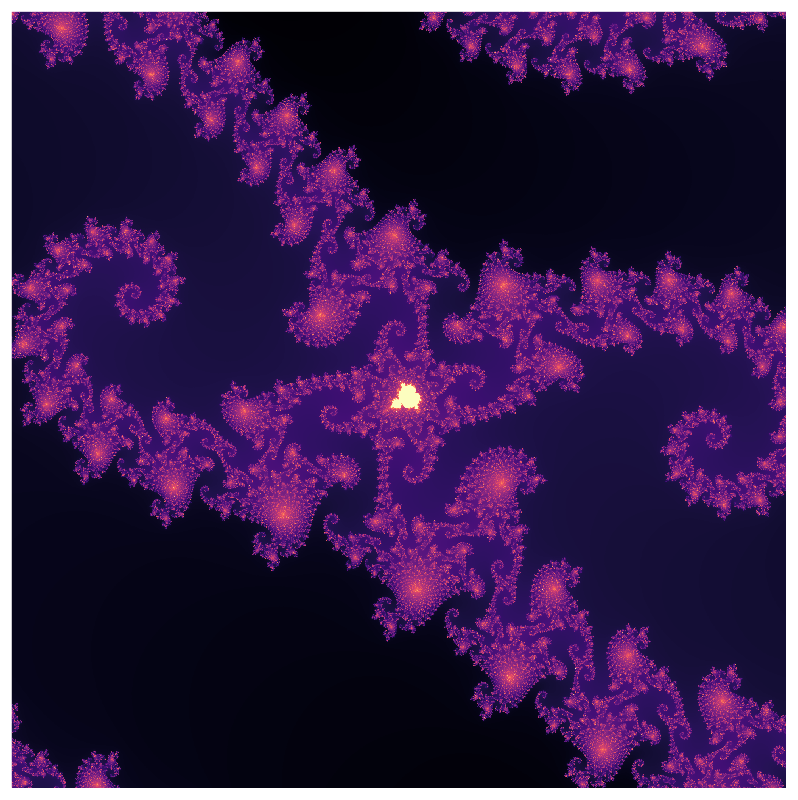

In [10]:
heatmap(log.(Array(img_ref)[1:4:end, 1:4:end] .+ 1); c = :magma, aspect_ratio = 1,
        axis = false, ticks = false, colorbar = false, size = (800, 800))

The bright blob in the middle is a tiny copy of the whole Mandelbrot set, deep inside
the boundary. Almost every pixel in this window lies close to the boundary of the set,
which is what makes this window expensive: most pixels need hundreds of iterations.

How large the gap is depends a lot on the GPU. Consumer and workstation cards
(RTX, L40S) run Float64 at 1/64 of the Float32 rate. Datacenter cards (A100, H100)
run it at 1/2. Apple's Metal has no Float64 at all.

### When Float32 is not good enough

Float32 has about 7 significant digits. Our window is 10⁻⁴ wide and split into 8192
pixels, so neighbouring pixels are about 1.2 × 10⁻⁸ apart. Near x ≈ -0.74, the gap
between two neighbouring Float32 numbers is about 6 × 10⁻⁸. So several pixels in a row
get **the same** Float32 coordinate:

In [11]:
@printf("distinct x coordinates:  Float32 %5d   Float64 %5d   (of %d pixels)\n",
        length(unique(Array(xs32))), length(unique(Array(xs64))), N)
@printf("distinct y coordinates:  Float32 %5d   Float64 %5d   (of %d pixels)\n",
        length(unique(Array(ys32))), length(unique(Array(ys64))), N)

distinct x coordinates:  Float32  1679   Float64  8192   (of 8192 pixels)
distinct y coordinates:  Float32  6711   Float64  8192   (of 8192 pixels)


In x, only about one in five pixel columns has its own coordinate: the "8192 pixel
wide" Float32 image really has stripes about five pixels wide. On top of that, the
rounding errors during the 2000 iterations are amplified near the boundary of the set.
Comparing with the Float64 image:

In [12]:
println("Float32 vs Float64: ", compare(img, img64))

Float32 vs Float64: 17170994 of 67108864 pixels differ (25.587%), largest difference 1837 iterations


About a quarter of all pixels get a different iteration count, some of them off by
almost the full 2000. So in this window the Float32 image is visibly wrong in its details.
Here is a 256 × 256 pixel crop at full resolution, Float32 next to Float64:

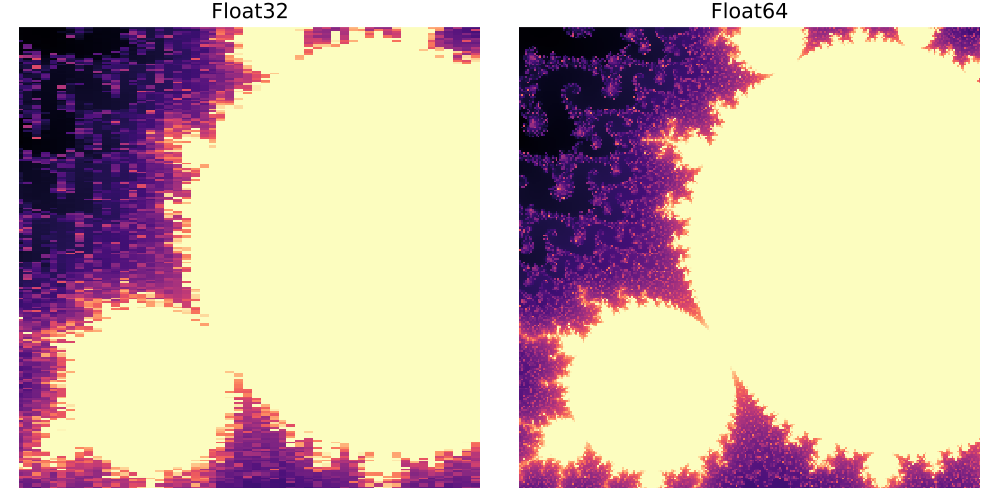

In [13]:
r = 4001:4256
opts = (c = :magma, aspect_ratio = 1, axis = false, ticks = false, colorbar = false)
p32 = heatmap(log.(Array(img_ref)[r, r] .+ 1); title = "Float32", opts...)
p64 = heatmap(log.(Array(img64)[r, r] .+ 1);   title = "Float64", opts...)
plot(p32, p64; layout = (1, 2), size = (1000, 500))

The Float32 image is made of horizontal bars about five pixels wide: those are the pixels
that share one Float32 x coordinate. And even where the bars are, the colours are mostly
noise: the fine structure that Float64 shows is gone. This is a
*math* limit, not a code limit: no kernel trick fixes it. The options are Float64
(correct, but slow on most GPUs), or better math: e.g. perturbation theory, which
computes one reference orbit in high precision and all other pixels as small
differences to it in Float32. That is how deep-zoom Mandelbrot renderers work.

For the rest of this notebook we stay with Float32, because that is what the lab
used and we want comparable numbers.

## 2. The speed limit

Before optimizing, it helps to know the floor. What would this kernel cost if it
did no arithmetic at all, and only moved its data?

Inputs: `xs` and `ys`, 2 × 8192 floats = 64 KB. Negligible.
Output: the image, 8192 × 8192 × 4 bytes = 268 MB. Written once.

So the only real data movement is writing the image. Let's measure that in
three ways: a kernel that only writes, the vendor `fill!`, and a device-to-device
copy.

In [14]:
@kernel inbounds = true function write_kernel!(img, val)
    i, j = @index(Global, NTuple)
    img[i, j] = val
end

nbytes   = sizeof(img)
img2     = similar(img)
k_write  = write_kernel!(backend, (32, 8), size(img))

t_write  = bench(() -> k_write(img2, UInt32(1)), backend)
t_fill   = bench(() -> fill!(img2, UInt32(0)), backend)
t_dcopy  = bench(() -> copyto!(img2, img), backend)

@printf("write kernel:      %7.3f ms   %6.0f GB/s\n", 1e3t_write, nbytes / t_write / 1e9)
@printf("fill! (memset):    %7.3f ms   %6.0f GB/s\n", 1e3t_fill,  nbytes / t_fill / 1e9)
@printf("copyto! (D -> D):  %7.3f ms   %6.0f GB/s\n", 1e3t_dcopy, 2nbytes / t_dcopy / 1e9)
@printf("Mandelbrot (F32):  %7.3f ms   = %.0fx the write-only floor\n", 1e3t_f32, t_f32 / t_write)

write kernel:        0.402 ms      668 GB/s
fill! (memset):      0.392 ms      684 GB/s
copyto! (D -> D):    0.826 ms      650 GB/s
Mandelbrot (F32):    4.992 ms   = 12x the write-only floor


The Mandelbrot kernel takes many times longer than just writing its output.
It is **compute bound**: the time goes into arithmetic, not into memory.
This tells us where to look. Memory tricks (shared memory, caching, coalescing)
can win us at most the write time. The arithmetic and the control flow are where
the rest of the time goes.

There is one more data movement we haven't counted: getting the image back to
the CPU, e.g. to plot it. That goes over PCIe, not over GPU memory:

In [15]:
img_host = Array{UInt32}(undef, N, N)
t_d2h = bench(() -> copyto!(img_host, img), backend)
@printf("copyto! (D -> H):  %7.3f ms   %6.0f GB/s\n", 1e3t_d2h, nbytes / t_d2h / 1e9)

copyto! (D -> H):   12.319 ms       22 GB/s


PCIe is roughly 10 to 100 times slower than GPU memory. Compare this number with
the kernel time.

Rule: keep data on the GPU. Move it to the host only when you really need it there.
(Pinned host memory, `CUDA.pin(img_host)`, makes this copy faster, but it is still
PCIe.)

## 3. Static workgroup size

So far we let KA choose the workgroup size at launch time. As in Part 2 of the
JuliaCon workshop, we can fix the workgroup size, and also the ndrange, when we
instantiate the kernel:

In [16]:
k_wg   = mandelbrot_kernel!(backend, (32, 8))              # static WG, dynamic ndrange
k_stat = mandelbrot_kernel!(backend, (32, 8), size(img))   # both static

t_wg   = bench(() -> k_wg(img, xs32, ys32, mi32, escape_complex; ndrange = size(img)), backend)
t_stat = bench(() -> k_stat(img, xs32, ys32, mi32, escape_complex), backend)

@printf("dynamic WG, dynamic ndrange: %8.3f ms\n", 1e3t_f32)
@printf("static  WG, dynamic ndrange: %8.3f ms\n", 1e3t_wg)
@printf("static  WG, static  ndrange: %8.3f ms\n", 1e3t_stat)

dynamic WG, dynamic ndrange:    4.992 ms
static  WG, dynamic ndrange:    4.496 ms
static  WG, static  ndrange:    4.422 ms


With the sizes known at compile time, the compiler turns the integer divisions that
map the flat thread id to `(i, j)` into shifts, simplifies the bounds check and
knows the maximum number of threads per block (launch bounds). For the copy kernel
in the workshop this was a big win, because the copy does nothing else.

Here the index computation happens once per pixel, while the loop runs up to 2000
iterations per pixel, so one might expect almost no gain. We still get about 10%:
with dynamic sizes the index computation needs 64-bit integer divisions, which GPUs
emulate in software at the cost of dozens of instructions each. Not much compared with
the copy kernel in the workshop, but not nothing either.

The first workgroup dimension (32) runs along `i`, the contiguous dimension in
Julia's column-major arrays, so neighbouring work items write neighbouring memory.

From here on all kernels are launched with `k_stat`.

## 4. Arithmetic: real numbers and muladd

`Complex` is convenient, but it hides what the hardware actually computes.
Per iteration, `z * z + c` and `abs2(z)` together are 6 multiplications and
5 additions, and `x*x` and `y*y` are computed twice (once in the square,
once in `abs2`). Written out with real numbers, we can reuse them:

In [17]:
function escape_real(cx, cy, maxiter)
    x = y = zero(cx)
    x2 = y2 = zero(cx)
    iter = zero(maxiter)
    while x2 + y2 <= 4 && iter < maxiter
        y = 2 * x * y + cy
        x = x2 - y2 + cx
        x2, y2 = x * x, y * y
        iter += one(iter)
    end
    return iter
end

t_real = bench(() -> k_stat(img, xs32, ys32, mi32, escape_real), backend)
@printf("Complex:  %8.3f ms\n", 1e3t_stat)
@printf("real:     %8.3f ms\n", 1e3t_real)
println("real vs Complex: ", compare(img, img_ref))

Complex:     4.422 ms
real:        4.248 ms
real vs Complex: 14859582 of 67108864 pixels differ (22.143%), largest difference 1841 iterations


In exact arithmetic this is the same computation, but the image is **not** bit-identical.
GPUs have a fused multiply-add (FMA) instruction: `a * b + c` in one instruction,
rounded once instead of twice. On the CPU, Julia only fuses when you ask for it.
The CUDA backend, however, fuses multiply-adds by default (like `nvcc --fmad=true`),
and which pairs get fused depends on how the expression is written. So the two
versions round slightly differently. You can check with

    @device_code_ptx k_stat(img, xs32, ys32, mi32, escape_real)

and look for `fma.rn.f32`.

### What does a mismatch mean?

A mismatch is a pixel whose iteration count differs between the two versions, i.e. a
pixel that gets a different colour. It happens near the boundary of the set. There
the iteration is chaotic: a difference in the last bit of z roughly doubles with every
iteration, so after a few dozen iterations the two orbits have nothing in common
anymore, and they cross |z| > 2 at different steps. Pixels away from the boundary escape
quickly (or converge inside the set), before the rounding difference can grow, so
they agree.

Our window is a tiny piece of the boundary, so almost every pixel is "near the
boundary", and over 20% of them change. In the tutorial's full view of the set, the
same change affected only 0.3% of the pixels.

Neither version is "more correct", both are equally good Float32 approximations.
Compare the numbers with the Float32 vs Float64 comparison in section 1: rounding the
same Float32 computation differently changes about as many pixels as switching to
Float64 does. In other words, in this window the fine detail of the Float32 image is
essentially rounding noise. And in general: testing with `==` against a reference stops
working as soon as the compiler, or you, reorder the arithmetic.

We can also write the FMAs explicitly with `muladd`, which states the intent and
makes the fusion portable across backends:

In [18]:
function escape_fma(cx, cy, maxiter)
    x = y = zero(cx)
    iter = zero(maxiter)
    while iter < maxiter
        y2 = y * y
        muladd(x, x, y2) <= 4 || break        # |z|² = x² + y²
        x_new = muladd(x, x, cx - y2)          # x² - y² + cx
        y     = muladd(x + x, y, cy)           # 2xy + cy
        x     = x_new
        iter += one(iter)
    end
    return iter
end

t_fma = bench(() -> k_stat(img, xs32, ys32, mi32, escape_fma), backend)
img_fma = copy(img)
@printf("muladd:   %8.3f ms\n", 1e3t_fma)
println("muladd vs Complex: ", compare(img, img_ref))

muladd:      4.232 ms
muladd vs Complex: 17404076 of 67108864 pixels differ (25.934%), largest difference 1875 iterations


On CUDA this is barely faster than `escape_real`, because the compiler had already
fused most of it for us. On a backend that does not fuse by default it can matter more.
From here on, `img_fma` is the reference: all later versions do exactly the same
arithmetic, so they must agree with it bit for bit.

## 5. Branchless inner loop

Every iteration of the `while` loop does a comparison and a branch, which is
a noticeable fraction of a 6-instruction loop body. We can instead run K iterations
without any branch, and only check for escape after every K steps:

In [19]:
function escape_unrolled(cx, cy, maxiter, ::Val{K}) where {K}
    x = y = zero(cx)
    iter  = zero(maxiter)
    alive = true
    for _ in 1:cld(maxiter, K)
        for _ in 1:K                           # K is known at compile time -> fully unrolled
            y2 = y * y
            alive &= muladd(x, x, y2) <= 4     # once escaped, stays escaped
            iter  += alive                     # Bool -> 0 or 1, no branch
            x_new = muladd(x, x, cx - y2)
            y     = muladd(x + x, y, cy)
            x     = x_new
        end
        alive || break                         # the only branch, once every K steps
    end
    return min(iter, maxiter)
end

escape_unrolled (generic function with 1 method)

Three details make this give exactly the same counts as `escape_fma`:

- The `alive` flag is sticky. After a pixel escapes we keep iterating (z grows to
  `Inf`, then `NaN`), but the counter no longer moves.
- We count with the state *before* each step, just like the `while` condition.
- The loop can overshoot `maxiter` by up to K-1 steps, so we clamp with `min`.

In [20]:
for K in (1, 2, 4, 8, 16)
    v = Val(K)            # capture Val(K), not K: keeps K a compile-time constant in the kernel
    f = (cx, cy, m) -> escape_unrolled(cx, cy, m, v)
    t = bench(() -> k_stat(img, xs32, ys32, mi32, f), backend)
    @printf("K = %2d:   %8.3f ms   %s\n", K, 1e3t, compare(img, img_fma))
end

escape_unrolled8(cx, cy, m) = escape_unrolled(cx, cy, m, Val(8))
t_unr = bench(() -> k_stat(img, xs32, ys32, mi32, escape_unrolled8), backend);

K =  1:      5.879 ms   0 of 67108864 pixels differ (0.000%), largest difference 0 iterations
K =  2:      4.424 ms   0 of 67108864 pixels differ (0.000%), largest difference 0 iterations
K =  4:      3.974 ms   0 of 67108864 pixels differ (0.000%), largest difference 0 iterations
K =  8:      3.884 ms   0 of 67108864 pixels differ (0.000%), largest difference 0 iterations
K = 16:      3.728 ms   0 of 67108864 pixels differ (0.000%), largest difference 0 iterations


A larger K means fewer branches, but more wasted iterations after a pixel has
escaped. With K = 1 we pay for the flag and the counter without saving any branches.

The wasted iterations after escape are cheaper than they look: a warp runs until its
slowest work item is done anyway (more on that in the next section), so they mostly
fill time in which that work item would otherwise sit idle.

## 6. Divergence

Remember the lockstep execution from the tutorial: the GPU runs 32 work items together
as one **warp**. Each work item occupies one of the 32 **lanes** of the warp, and since
our kernel has one work item per pixel, one lane = one pixel. The workgroup shape only
decides which 32 pixels end up in the same warp.

The warp moves on as a whole, so it takes as long as its slowest pixel. Lanes whose
pixel has already escaped cannot leave; they wait. With 4 lanes instead of 32:

```
iteration:   1 ........ 100 ............................ 500
lane 1:      ██████████████ (done)  · · · · · · · · · · · ·  waiting
lane 2:      ██████████████ (done)  · · · · · · · · · · · ·  waiting
lane 3:      ██████████████ (done)  · · · · · · · · · · · ·  waiting
lane 4:      ██████████████████████████████████████████████  working
```

The warp is busy for 500 iterations, so it uses 4 × 500 = 2000 lane slots, but only
100 + 100 + 100 + 500 = 800 of them do real computation. Its efficiency is 800 / 2000 = 0.4:
60% of the time, lanes are just waiting. This is called **warp divergence**.

We can measure this from the finished image alone, without touching the GPU: for each
group of 32 pixels that share a warp, the useful work is the sum of their iteration
counts, the time spent is 32 × the largest count.

In [21]:
function warp_efficiency(img, h, w)          # warp covers an h × w tile of pixels
    useful = spent = 0
    for j in 1:w:size(img, 2), i in 1:h:size(img, 1)
        tile = @view img[i:i+h-1, j:j+w-1]
        useful += sum(Int, tile)
        spent  += length(tile) * maximum(tile)
    end
    return useful / spent
end

img_h = Array(img_fma);

With workgroup size `(32, 8)`, the first 32 work items (one warp) are 32 consecutive `i`
in the same column: a 32 × 1 strip of pixels. Since neighbouring pixels tend to have
similar counts, a more compact, square-ish footprint should waste less. A workgroup of
`(h, 256 ÷ h)` gives warps that cover h × (32 ÷ h) pixels. Let's predict the efficiency
from the image, and measure the actual runtime:

In [22]:
t_wgs = Dict{Int,Float64}()
for h in (32, 16, 8, 4, 2)
    wg = (h, 256 ÷ h)
    k  = mandelbrot_kernel!(backend, wg, size(img))
    t  = bench(() -> k(img, xs32, ys32, mi32, escape_unrolled8), backend)
    t_wgs[h] = t
    @printf("workgroup %-9s warp = %2d × %-2d pixels:  %7.3f ms   predicted efficiency %.2f\n",
            string(wg), h, 32 ÷ h, 1e3t, warp_efficiency(img_h, h, 32 ÷ h))
end

workgroup (32, 8)   warp = 32 × 1  pixels:    3.913 ms   predicted efficiency 0.62
workgroup (16, 16)  warp = 16 × 2  pixels:    3.501 ms   predicted efficiency 0.69
workgroup (8, 32)   warp =  8 × 4  pixels:    3.341 ms   predicted efficiency 0.75
workgroup (4, 64)   warp =  4 × 8  pixels:    3.331 ms   predicted efficiency 0.77
workgroup (2, 128)  warp =  2 × 16 pixels:    3.366 ms   predicted efficiency 0.77


The compact footprints write less contiguous memory per warp, but we are compute
bound, so that hardly matters. The prediction from the image and the measured time
move together: going from 0.62 to 0.77 efficiency predicts about 1.24x, and we measure
about 1.17x. Not all of the waste is divergence, so the prediction is an upper bound.
This is a free optimization: one changed number in the launch.

### Grouping pixels by cost

Even the best footprint leaves a lot of waste. The ideal would be warps whose 32 pixels
all need the same number of iterations. We can't know the counts in advance (that would
be the computation itself), but we can **predict** them cheaply: compute a low-resolution
image first, with every 4th pixel in each direction (1/16 of the work), and use its
counts as the estimate for the full image. Then we sort all pixels by their predicted
cost and hand them out in that order, so each warp gets pixels with similar estimates.

```
unsorted (neighbouring pixels):            sorted by count:
lane 1: ████ · · · · · · · · · ·           lane 1: ██████████████
lane 2: ██████████████ (slowest)           lane 2: ██████████████
lane 3: ██████ · · · · · · · · ·           lane 3: █████████████
lane 4: ██ · · · · · · · · · · ·           lane 4: █████████████
→ lots of waiting                          → almost no waiting
```

To see what grouping can gain at best, we also sort by the **exact** counts, which we
know from `img_fma`. That's cheating, but it gives the upper bound.

In this experiment we only time the computation in sorted order. The low-res pass is
timed separately, and the sorting runs on the CPU and is not timed at all.

The kernel works on a 1D list of pixels. Work item `k` computes pixel `perm[k]` and
writes the result to position `k` of a 1D buffer, so the writes stay contiguous.
A second kernel puts the results back in place.

In [23]:
@kernel inbounds = true function mandelbrot_sorted_kernel!(out, @Const(xs), @Const(ys), maxiter, escape, @Const(perm), ny)
    k = @index(Global, Linear)
    j, i = divrem(perm[k] - one(ny), ny)     # linear index -> (i, j), 0-based
    out[k] = escape(xs[j + 1], ys[i + 1], maxiter)
end

@kernel inbounds = true function unsort_kernel!(img, @Const(out), @Const(perm))
    k = @index(Global, Linear)
    img[perm[k]] = out[k]
end

# efficiency of handing out pixels in the order `perm`, 32 at a time
function warp_efficiency_perm(counts, perm)
    useful = spent = 0
    for k in 1:32:length(perm)
        c = @view counts[perm[k:min(k + 31, end)]]
        useful += sum(Int, c)
        spent  += length(c) * maximum(c)
    end
    return useful / spent
end

warp_efficiency_perm (generic function with 1 method)

The low-resolution prediction. Its coordinates are exactly every 4th coordinate of the
full image:

In [24]:
s = 4
img_low = KernelAbstractions.zeros(backend, UInt32, N ÷ s, N ÷ s)
xs_low, ys_low = xs32[1:s:end], ys32[1:s:end]
k_low = mandelbrot_kernel!(backend, (32, 8), size(img_low))
t_low = bench(() -> k_low(img_low, xs_low, ys_low, mi32, escape_unrolled8), backend)
low   = Array(img_low)
pred  = [low[cld(i, s), cld(j, s)] for i in 1:N, j in 1:N]
@printf("low-res pass (1/16 of the pixels): %7.3f ms\n", 1e3t_low)

low-res pass (1/16 of the pixels):   0.289 ms


Three orders: unsorted (the plain column-major order, to measure the cost of the
indirection itself), sorted by the low-res prediction, and sorted by the exact counts.
We sort in descending order: the most expensive pixels go first, so the GPU does not end
with a few long-running blocks while the rest of it sits idle.

In [25]:
counts  = vec(img_h)
orders  = [
    ("unsorted",            Int32.(1:N*N)),
    ("low-res prediction",  Int32.(sortperm(vec(pred); rev = true))),
    ("exact counts (cheat)", Int32.(sortperm(counts; rev = true))),
]

out      = similar(img, N * N)
k_sorted = mandelbrot_sorted_kernel!(backend, 256, (N * N,))
k_unsort = unsort_kernel!(backend, 256, (N * N,))
t_sorted = Dict{String,Float64}()

for (name, perm_h) in orders
    perm = adapt(backend, perm_h)
    t    = bench(() -> k_sorted(out, xs32, ys32, mi32, escape_unrolled8, perm, Int32(N)), backend)
    t_un = bench(() -> k_unsort(img, out, perm), backend)
    t_sorted[name] = t
    @printf("%-21s compute %7.3f ms   unsort %6.3f ms   predicted efficiency %.2f\n",
            name, 1e3t, 1e3t_un, warp_efficiency_perm(counts, perm_h))
    println("    ", compare(img, img_fma))
end

unsorted              compute   3.980 ms   unsort  1.159 ms   predicted efficiency 0.62
    0 of 67108864 pixels differ (0.000%), largest difference 0 iterations
low-res prediction    compute   3.594 ms   unsort  2.005 ms   predicted efficiency 0.68
    0 of 67108864 pixels differ (0.000%), largest difference 0 iterations
exact counts (cheat)  compute   2.755 ms   unsort  2.422 ms   predicted efficiency 1.00
    0 of 67108864 pixels differ (0.000%), largest difference 0 iterations


What this shows:

- The indirection itself costs a few percent (unsorted 1D vs the 2D kernel with the same
  32 × 1 warp footprint).
- The exact sort removes divergence completely (efficiency 1.00) and speeds up the
  computation by about 1.4x over unsorted. That is the most that grouping pixels could
  ever give. It is less than the predicted 1.6x: once divergence is gone, other limits
  take over (the `K = 8` rounding, reading `perm`, the arithmetic itself).
- The low-res prediction barely helps, and it is worse than simply choosing the 8 × 4
  warp footprint, which costs nothing. In this window the iteration counts are chaotic at
  the pixel scale: a pixel's count is poorly predicted by a coarse sample, and sorting
  by that prediction throws away the one thing that does predict it well, namely its
  direct neighbours. The compact warp footprint exploits exactly that.
- The unsort scatters its writes all over memory and costs more than the sort gains.
  Even the cheating version is a net loss once you count it.

So in this window: use the compact footprint, and leave sorting alone. A real gain from
grouping would need a much better predictor than a coarse image, or the lane-refilling
approach, which needs no prediction at all: each lane fetches a new pixel from a global
counter (`@atomic`) as soon as its current pixel escapes.

## 7. Memory: a smaller output type

Does a memory trick help? Compare the kernel time with the write-only floor from
section 2 to see how much there could be to gain.

The simplest trick: write fewer bytes. The iteration count never exceeds
`maxiter = 2000`, so it fits in a `UInt16` (up to 65535). That halves the bytes written,
from 268 MB to 134 MB. None of the per-pixel functions need to change: they take their
integer type from `maxiter`, so passing a `UInt16` makes the whole computation use
`UInt16` counters.

In [26]:
img16     = KernelAbstractions.zeros(backend, UInt16, N, N)
img16_w   = similar(img16)                             # scratch array for the write-only floor
mi16      = UInt16(maxiter)
k_stat16  = mandelbrot_kernel!(backend, (32, 8), size(img16))
k_write16 = write_kernel!(backend, (32, 8), size(img16))

t_unr16   = bench(() -> k_stat16(img16, xs32, ys32, mi16, escape_unrolled8), backend)
t_write16 = bench(() -> k_write16(img16_w, UInt16(1)), backend)

@printf("UInt32 image: %7.3f ms   (write-only floor %6.3f ms)\n", 1e3t_unr, 1e3t_write)
@printf("UInt16 image: %7.3f ms   (write-only floor %6.3f ms)\n", 1e3t_unr16, 1e3t_write16)
println("UInt16 vs UInt32: ", compare(img16, img_fma))

UInt32 image:   3.907 ms   (write-only floor  0.402 ms)
UInt16 image:   3.817 ms   (write-only floor  0.202 ms)
UInt16 vs UInt32: 0 of 67108864 pixels differ (0.000%), largest difference 0 iterations


(We use the unrolled version from section 5 here.)

The write-only floor halves, but the kernel gains much less than that. A kernel's time
is not "compute time + write time": the stores are handed off to the memory system
and happen while other warps keep computing. As long as the kernel is compute bound,
the writes are mostly hidden, and making them cheaper barely shows up. This is the
same "know your floor" lesson from the other side: only optimize memory traffic once
memory is actually the limit.

The same halving applies to the copy back to the CPU, which in absolute terms is the
much bigger saving:

In [27]:
img16_host = Array{UInt16}(undef, N, N)
t_d2h16 = bench(() -> copyto!(img16_host, img16), backend)
@printf("copy to CPU:  UInt32 %7.3f ms   UInt16 %7.3f ms\n", 1e3t_d2h, 1e3t_d2h16)

copy to CPU:  UInt32  12.319 ms   UInt16   6.500 ms


The general lesson: when a kernel is memory bound, count bytes, and the cheapest
byte is the one you never write. Use the smallest type that holds your data
(`UInt8` would even do for `maxiter ≤ 255`). The caveat is that you must know the range:
a count above 65535 would silently wrap around in a `UInt16`.

## Summary

In [28]:
results = [
    ("1. Float64 / Int64",                    t_f64),
    ("1. Float32 / UInt32",                   t_f32),
    ("3. + static workgroup & ndrange",       t_stat),
    ("4. + real arithmetic",                  t_real),
    ("4. + muladd",                           t_fma),
    ("5. + branchless, K = 8",                t_unr),
    ("6. + warp = 8 × 4 pixels",              t_wgs[8]),
    ("6.   sorted by low-res (compute only)", t_sorted["low-res prediction"]),
    ("6.   sorted exactly (compute only)",    t_sorted["exact counts (cheat)"]),
    ("7.   UInt16 output (on 5.)",            t_unr16),
]
for (name, t) in results
    @printf("%-38s %8.3f ms   %6.2fx vs Float32 baseline\n", name, 1e3t, t_f32 / t)
end
@printf("%-38s %8.3f ms\n", "write-only floor (UInt32)", 1e3t_write)
@printf("%-38s %8.3f ms\n", "write-only floor (UInt16)", 1e3t_write16)
@printf("%-38s %8.3f ms\n", "copy image to CPU (UInt32)", 1e3t_d2h)
@printf("%-38s %8.3f ms\n", "copy image to CPU (UInt16)", 1e3t_d2h16)

1. Float64 / Int64                      217.464 ms     0.02x vs Float32 baseline
1. Float32 / UInt32                       4.992 ms     1.00x vs Float32 baseline
3. + static workgroup & ndrange           4.422 ms     1.13x vs Float32 baseline
4. + real arithmetic                      4.248 ms     1.18x vs Float32 baseline
4. + muladd                               4.232 ms     1.18x vs Float32 baseline
5. + branchless, K = 8                    3.907 ms     1.28x vs Float32 baseline
6. + warp = 8 × 4 pixels                  3.341 ms     1.49x vs Float32 baseline
6.   sorted by low-res (compute only)     3.594 ms     1.39x vs Float32 baseline
6.   sorted exactly (compute only)        2.755 ms     1.81x vs Float32 baseline
7.   UInt16 output (on 5.)                3.817 ms     1.31x vs Float32 baseline
write-only floor (UInt32)                 0.402 ms
write-only floor (UInt16)                 0.202 ms
copy image to CPU (UInt32)               12.319 ms
copy image to CPU (UInt16)           

Takeaways:

- **Know your floor.** Measure what just moving the data costs. That tells you
  whether you are memory bound (then count bytes, like `T_eff` in the workshop) or
  compute bound (then count instructions and branches, like here).
- **Types first.** Float32 unless you need more, and check whether you do: in this
  window Float32 is already too coarse to resolve the pixels.
- **Specialise launches.** Static workgroup size and ndrange are free, and sometimes
  matter a lot (memory-bound kernels) and sometimes barely (this one).
- **Help the compiler.** Reuse values, `muladd`, fewer branches in the hot loop.
  Some of these change rounding, so test with a tolerance, not `==`.
- **Look at the waiting, not just the work.** Lanes that sit idle in a warp cost as
  much as lanes that compute. Choosing which pixels share a warp was the biggest free
  win here.
- **Then step back and think about the math.** In this window the real limit is not
  speed but Float32 precision, and no kernel trick fixes that: it takes Float64 or a
  better algorithm such as perturbation theory.

---

*This notebook was generated using [Literate.jl](https://github.com/fredrikekre/Literate.jl).*